# Лабораторная работа № 2.3
---
«Сравнение моделей машинного обучения на основе Python библиотеки lazypredict»

Рязанцев Георгий Борисович

## 1. Установка и импорт библиотек

In [1]:
#импортируем необходимые библиотеки
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import lazypredict
from lazypredict.Supervised import LazyRegressor

In [2]:
# Дополнительно: версии библиотек (в методичке отсутствует)
# Установка в методичке выполняется в терминале: pip install lazypredict
# В ноутбуке это можно сделать так (раскомментировать при необходимости): %pip install lazypredict
import importlib.metadata as md

for pkg in ['lazypredict', 'scikit-learn', 'pandas', 'numpy', 'seaborn', 'matplotlib', 'xgboost', 'lightgbm', 'catboost', 'tensorflow']:
    try:
        print('%-13s %s' % (pkg, md.version(pkg)))
    except md.PackageNotFoundError:
        print('%-13s не установлена' % pkg)

lazypredict   0.4.0
scikit-learn  1.8.0
pandas        2.3.3
numpy         1.26.4
seaborn       0.13.2
matplotlib    3.10.8
xgboost       не установлена
lightgbm      не установлена
catboost      не установлена
tensorflow    не установлена


**Результат и отличия от описания в методичке.** Импорт (рис. 2.18) выполняется без изменений. В теоретической части методичка описывает библиотеку точнее, чем она работает на самом деле; на ход работы это не влияет, но влияет на то, как нужно читать результаты:

| Утверждение методички | Что происходит на самом деле | Как это влияет на работу |
|---|---|---|
| LazyPredict «автоматически выбирает лучшую модель» | Библиотека обучает все доступные ей модели и возвращает таблицу метрик, отсортированную по одному из показателей. Выбор лучшей модели делает человек, сравнивая таблицу | «Лучшую модель» нужно выбирать самим и обосновывать выбор (разделы 6–7) |
| «Автоматически оптимизирует гиперпараметры» | Модели обучаются с параметрами по умолчанию, подбора параметров нет | Плохой результат отдельных моделей (например, `SVR`, `MLPRegressor`) означает «плохо при настройках по умолчанию», а не «модель не подходит для задачи» |
| «Автоматически определяет тип проблемы» | Тип задачи задаётся выбором класса вручную: `LazyRegressor` для числовой цели, `LazyClassifier` для классов. Сама методичка ниже говорит то же («может также строить… LazyClassifier()») | Для цены продажи используется `LazyRegressor`, для банкротства (самостоятельная работа) — `LazyClassifier` |
| Нужны `xgboost`, `lightgbm`, `catboost` и `TensorFlow` | `TensorFlow` в этой работе не используется. `xgboost` и `lightgbm` библиотека подключает, только если они установлены и работают | Состав таблицы моделей зависит от установленных пакетов (см. п. 4: `XGBRegressor` и `LGBMRegressor` в таблице отсутствуют) |

Версии из ячейки выше: `lazypredict` 0.4.0, `scikit-learn` 1.8.0, `pandas` 2.3.3, `seaborn` 0.13.2; `xgboost`, `lightgbm`, `catboost` и `tensorflow` **не установлены**. Результаты ниже получены в этом окружении; в другой версии библиотеки или с другими установленными пакетами состав и порядок моделей могут отличаться.

## 2. Загрузка данных и выбор переменных

In [3]:
#загрузим данные
data = pd.read_csv('Rural_prices.csv', sep=";", decimal=",")

#выберем переменные для модели
x1 = data.drop('sale price', axis=1)
y1 = data['sale price']

In [4]:
# Дополнительно: размер таблицы, пропуски и число различных значений в столбцах (в методичке отсутствует)
print('Размер таблицы:', data.shape)
print('Пропусков:', int(data.isna().sum().sum()), '| повторяющихся строк целиком:', int(data.duplicated().sum()))
print('Признаки x1:', x1.shape, '| целевая переменная y1:', y1.shape)
print()
print(data.head())
print()
print('Число различных значений в столбцах:')
print(data.nunique().to_string())

Размер таблицы: (546, 12)
Пропусков: 0 | повторяющихся строк целиком: 1
Признаки x1: (546, 11) | целевая переменная y1: (546,)

   sale price  lot size  #bedroom  #bath  #stories  driveway  rec room  \
0       42000      5850         3      1         2         1         0   
1       38500      4000         2      1         1         1         0   
2       49500      3060         3      1         1         1         0   
3       60500      6650         3      1         2         1         1   
4       61000      6360         2      1         1         1         0   

   basement  gas  air cond  #garage  desire loc  
0         1    0         0        1           0  
1         0    0         0        0           0  
2         0    0         0        0           0  
3         0    0         0        0           0  
4         0    0         0        0           0  

Число различных значений в столбцах:
sale price    219
lot size      284
#bedroom        6
#bath           4
#stories        4

**Результат.** Код совпадает с рис. 2.19. Датасет содержит 546 наблюдений и 12 столбцов (рис. 2.20): 11 признаков и целевая переменная `sale price`; в тексте методички «12 признаков, включая целевую» — это те же 12 столбцов. Параметры `sep=";"` и `decimal=","` нужны, потому что в файле разделитель столбцов — точка с запятой, а десятичный разделитель — запятая; при чтении «по умолчанию» таблица не разделилась бы на столбцы.

In [5]:
column_names = data.columns.tolist() 
print(column_names)

['sale price', 'lot size', '#bedroom', '#bath', '#stories', 'driveway', 'rec room', 'basement', 'gas', 'air cond', '#garage', 'desire loc']


**Отличие: описание переменных в методичке неточное.** Список названий столбцов совпадает с рис. 2.20, но часть пояснений методички не соответствует данным: четыре переменные описаны как «наличие» чего-либо, хотя по описательной статистике ниже это **количества**, а не признаки 0/1.

| Переменная | В методичке | По данным (min–max, среднее) | Тип |
|---|---|---|---|
| `sale price` | цена продажи | 25 000 – 190 000, ≈ 68 122 | числовая (целевая) |
| `lot size` | размер объекта недвижимости | 1 650 – 16 200, ≈ 5 150 | числовая; по названию — размер земельного участка, единицы измерения в методичке не указаны |
| `#bedroom` | наличие спальни | **1 – 6**, ≈ 2,97 | **число спален** |
| `#bath` | наличие ванной комнаты | **1 – 4**, ≈ 1,29 | **число ванных комнат** |
| `#stories` | этажность | 1 – 4, ≈ 1,81 | число этажей (описание верное) |
| `#garage` | наличие гаража | **0 – 3**, ≈ 0,69 | **число гаражных мест** |
| `driveway`, `rec room`, `basement`, `gas`, `air cond`, `desire loc` | наличие подъездной дороги, комнаты отдыха, подвала, газа, кондиционера, удобного расположения | 0 или 1 | бинарные признаки; доля единиц: 86 %, 18 %, 35 %, 4,6 %, 32 %, 23 % |

На ход работы это не влияет: `LazyRegressor` получает числовую матрицу, и для моделей разницы между «количеством комнат» и «признаком 0/1» нет. Влияние только на формулировки выводов: нельзя писать «наличие спальни повышает цену», правильно — «количество спален».

Типы подтверждаются ячейкой с числом различных значений: у `#bedroom` их 6, у `#bath`, `#stories` и `#garage` по 4, а ровно два значения (0 и 1) — только у шести бинарных столбцов.

In [6]:
data.describe()

,sale price,lot size,#bedroom,#bath,#stories,driveway,rec room,basement,gas,air cond,#garage,desire loc
count,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000
mean,68121.597070,5150.265568,2.965201,1.285714,1.807692,0.858974,0.177656,0.349817,0.045788,0.316850,0.692308,0.234432
std,26702.670926,2168.158725,0.737388,0.502158,0.868203,0.348367,0.382573,0.477349,0.209216,0.465675,0.861307,0.424032
min,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,49125.000000,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,62000.000000,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000
max,190000.000000,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000


**Результат совпадает с рис. 2.21:** 546 наблюдений; цена продажи: среднее 68 121,60, стандартное отклонение 26 702,67, минимум 25 000, квартили 49 125 / 62 000 / 82 000, максимум 190 000; остальные показатели, видимые на рисунке (среднее и отклонение `lot size`, `#bedroom`, `air cond`, `#garage`, `desire loc`, максимум `#garage`), тоже совпадают. Пропусков в данных нет. Эти значения используются ниже: максимум цены (190 000) задаёт предел шкалы RMSE на рис. 2.26, а стандартное отклонение (≈ 26 700) — ориентир ошибки «наивной» модели.

## 3. Разбиение на тренировочную и тестовую выборки

In [7]:
# Установим разбиение выборки в соотношении 80/20
X_train, X_test, Y_train, Y_test = train_test_split(x1, y1, test_size=0.2, random_state=None)

In [8]:
# Дополнительно: размеры выборок (в методичке отсутствует)
print('Обучающая выборка:', X_train.shape, '| тестовая выборка:', X_test.shape)

Обучающая выборка: (436, 11) | тестовая выборка: (110, 11)


**Результат и отличия.** Код совпадает с рис. 2.22: соотношение 80/20, `random_state=None`. Получается 436 обучающих и 110 тестовых наблюдений (20 % от 546, округление вверх).

Главное следствие параметра `random_state=None` — **разбиение случайно при каждом запуске**. В отличие от работы 2.6, где `random_state=0` давал воспроизводимый результат, здесь числа в таблицах и на графиках после перезапуска будут немного другими, и совпасть с рисунками методички до знака они не могут. На выводы это влияет слабо, пока сохраняется общая картина (деревья и ансамбли впереди, линейные модели в середине, `SVR`/`MLP` в конце), но порядок близких по качеству моделей на 110 тестовых объектах может меняться. Поэтому в разделе 7 добавлена проверка на нескольких разбиениях.

## 4. Построение LazyRegressor

In [9]:
# определим и построим lazyregressor
clf = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None)
models_train,predictions_train = clf.fit(X_train, X_train, Y_train, Y_train)
models_test,predictions_test = clf.fit(X_train, X_test, Y_train, Y_test)

In [10]:
print(models_train)
print(predictions_train.shape)
print(predictions_train.columns)

                               Adjusted R-Squared  R-Squared          RMSE  \
Model                                                                        
DecisionTreeRegressor                    0.997278   0.997347   1378.985744   
ExtraTreeRegressor                       0.997278   0.997347   1378.985744   
ExtraTreesRegressor                      0.997278   0.997347   1378.988405   
GaussianProcessRegressor                 0.989798   0.990056   2669.869990   
RandomForestRegressor                    0.948689   0.949986   5987.575638   
BaggingRegressor                         0.931531   0.933262   6916.595523   
GradientBoostingRegressor                0.873609   0.876805   9397.306787   
HistGradientBoostingRegressor            0.855121   0.858785  10061.145931   
KNeighborsRegressor                      0.760019   0.766088  12948.908410   
PoissonRegressor                         0.703983   0.711469  14381.465341   
AdaBoostRegressor                        0.687368   0.695273  14

In [11]:
# Дополнительно: состав таблицы моделей (в методичке отсутствует)
print('Число моделей: на обучающей выборке -', len(models_train), '| на тестовой -', len(models_test))
print('Столбцы таблицы метрик:', models_test.columns.tolist())
print('Названные в методичке, но отсутствующие в таблице:', [m for m in ('XGBRegressor', 'LGBMRegressor') if m not in models_test.index])
print('Строк с полностью совпадающими признаками (x1):', int(x1.duplicated(keep=False).sum()), 'из', len(x1))
print()
print(models_test.head(10).round(4).to_string())

Число моделей: на обучающей выборке - 40 | на тестовой - 40
Столбцы таблицы метрик: ['Adjusted R-Squared', 'R-Squared', 'RMSE', 'Time Taken']
Названные в методичке, но отсутствующие в таблице: ['XGBRegressor', 'LGBMRegressor']
Строк с полностью совпадающими признаками (x1): 31 из 546

               Adjusted R-Squared  R-Squared        RMSE  Time Taken
Model                                                               
SGDRegressor               0.5825     0.6247  15833.3985      0.0058
BayesianRidge              0.5825     0.6247  15833.8065      0.0063
RidgeCV                    0.5825     0.6246  15834.9247      0.0056
Ridge                      0.5819     0.6241  15845.0792      0.0087
LassoCV                    0.5819     0.6241  15845.2415      0.0248
LassoLars                  0.5819     0.6241  15846.4218      0.0057
Lasso                      0.5819     0.6241  15846.4241      0.0051
Lars                       0.5819     0.6241  15846.5132      0.0062
LarsCV                  

**Результат и отличия от методички.** Код совпадает с рис. 2.22, но результат и его использование отличаются в трёх местах.

**1. Какая переменная содержит таблицу метрик.** В методичке графики строятся по `predictions_train`, а в этой версии библиотеки метод `fit` возвращает таблицу метрик **первым** значением (`models_train`), а второе — таблицу прогнозов, которая пуста, пока не включён параметр `predictions=True`. Это видно по выводу ячейки с `print`: `predictions_train.shape = (0, 0)`, столбцов нет. Вероятно, в версии библиотеки, на которую опиралась методичка, второе значение дублировало таблицу метрик, поэтому построение по `predictions_train` там работало. В этой работе все графики строятся по `models_train` / `models_test`: код из методички с `predictions_train` дал бы ошибку (нет столбца `R-Squared`).

**2. Число моделей.** Построено 40 моделей, а не 35, как написано в тексте методички; на самом рис. 2.25 у методички 42 столбца, то есть текст расходится и с собственным рисунком. Число зависит от версии библиотеки и от того, какие пакеты установлены.

**3. Нет `XGBRegressor` и `LGBMRegressor`.** Методичка называет `XGBRegressor` среди лучших моделей, в нашей таблице его нет (как и `LGBMRegressor`). Причина подтверждена ячейкой с версиями: пакеты `xgboost` и `lightgbm` в окружении не установлены, а при `ignore_warnings=True` библиотека пропускает недоступные модели молча, без сообщения об ошибке. Влияние на работу: из списка лучших моделей `XGBRegressor` выпадает, вместо него в тройку лидеров на обучающей выборке попадает `ExtraTreesRegressor`; общий вывод (на обучающей выборке впереди деревья и их ансамбли) не меняется. Чтобы получить все 42 модели, как на рис. 2.25, достаточно выполнить `pip install xgboost lightgbm`.

Ещё одно замечание к ячейке с `fit`: первый вызов `clf.fit(X_train, X_train, Y_train, Y_train)` оценивает модели **на тех же данных, на которых они обучены**, а второй — на тестовых; методичка строит графики только по первому (см. следующий раздел).

## 5. Визуализация показателей эффективности (по обучающей выборке, как в методичке)

In [12]:
#визуализируем показатели эффективности моделей
# столбчатая диаграмма значений коэффициента детерминации
import matplotlib.pyplot as plt
import seaborn as sns

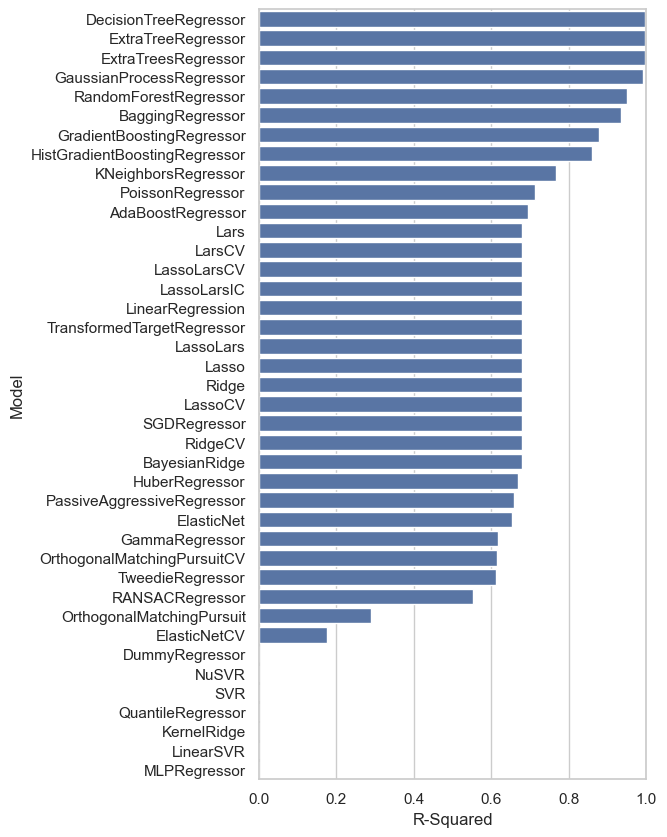

R-Squared < 0 на обучающей выборке: ['NuSVR', 'SVR', 'QuantileRegressor', 'KernelRidge', 'LinearSVR', 'MLPRegressor']
R-Squared = 0: ['DummyRegressor']


In [13]:
# столбчатая диаграмма значений коэффициента детерминации (R-Squared) на обучающей выборке
plt.figure(figsize=(5, 10))
sns.set_theme(style="whitegrid")
ax = sns.barplot(y=models_train.index, x="R-Squared", data=models_train)
ax.set(xlim=(0, 1))
plt.show()

# Дополнительно: модели с отрицательным R-Squared (на графике их столбцов нет)
print('R-Squared < 0 на обучающей выборке:', models_train.index[models_train['R-Squared'] < 0].tolist())
print('R-Squared = 0:', models_train.index[models_train['R-Squared'] == 0].tolist())

**Результат и отличия от рис. 2.24–2.25.** Код соответствует рис. 2.24 с заменой `predictions_train` на `models_train` (см. раздел 4). В исходной ячейке ноутбука отсутствовали `plt.figure(figsize=(5, 10))` и `sns.set_theme(...)`, из-за чего 40 столбцов на стандартном поле рисунка нечитаемы; строки возвращены по методичке. Служебный комментарий рис. 2.24 (`[0 если i < 0 иначе i …]`) — не код, а заготовка, она ничего не выполняет, поэтому удалена.

- **Лидеры по R² совпадают с методичкой, кроме `XGBRegressor`:** `DecisionTreeRegressor`, `ExtraTreeRegressor` и `ExtraTreesRegressor` (у всех троих R² = 0,9961 и RMSE ≈ 1 681 — метрики совпали до всех знаков), затем `GaussianProcessRegressor` (0,9910), `RandomForestRegressor` (0,9411), `BaggingRegressor` (0,9106), `GradientBoostingRegressor` (0,8553).
- **Утверждение методички «некорректный R² обозначается нулём» неверно.** Отрицательные значения библиотека не заменяет нулём: у `NuSVR` (−0,006), `SVR` (−0,047), `QuantileRegressor` (−0,048), `KernelRidge` (−5,77), `LinearSVR` (−6,35), `MLPRegressor` (−6,40) R² отрицателен, и столбцов на графике нет только потому, что ось ограничена `xlim=(0, 1)`. Ровно 0 у `DummyRegressor` (он всегда предсказывает среднее обучающей выборки, это нижняя «планка»). Отрицательный R² означает, что модель прогнозирует хуже, чем простое среднее.
- **Причина плохих результатов у `SVR`, `NuSVR`, `LinearSVR`, `KernelRidge`, `MLPRegressor`:** эти модели работают с параметрами по умолчанию, а цена имеет масштаб десятки тысяч (признаки библиотека масштабирует, целевую переменную — нет), поэтому модели не могут «дотянуться» до значений цены. Это согласуется со значениями RMSE ниже и не является недостатком самих методов.
- **Важное замечание, которого нет в методичке.** R² ≈ 0,996 у деревьев на обучающей выборке — признак **переобучения**: дерево без ограничения глубины запоминает обучающие объекты, и по этой метрике нельзя выбирать модель для прогноза новых цен (в разделе 6 видно, что на тесте эти же модели резко теряют качество). Ненулевой RMSE деревьев (≈ 1 681), вероятно, вызван объектами с одинаковыми признаками и разной ценой: в данных 31 строка из 546 имеет полностью совпадающие значения всех 11 признаков с другой строкой, и дерево не может их разделить.

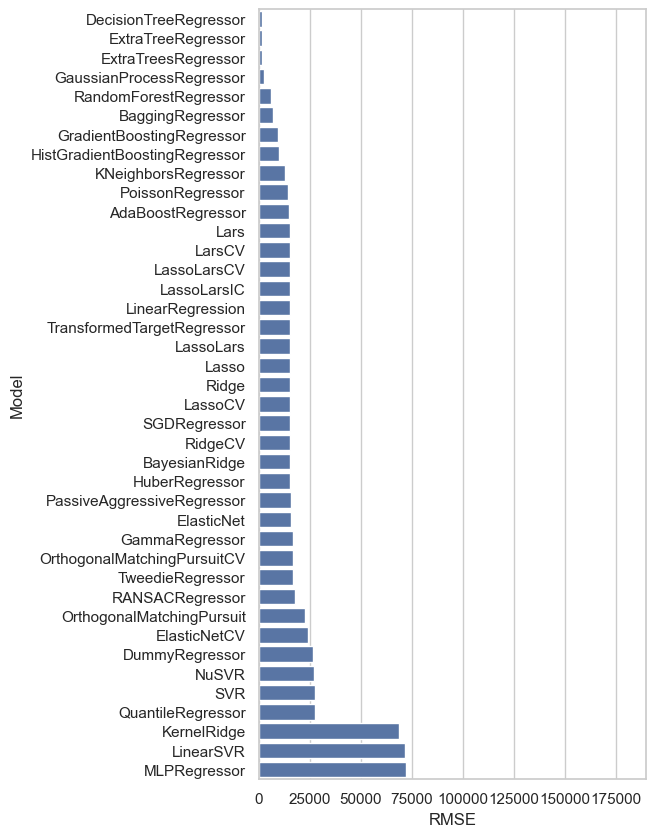

In [14]:
# столбчатая диаграмма значений RMSE (полная шкала: до максимальной цены продажи)
plt.figure(figsize=(5, 10))
sns.set_theme(style="whitegrid")
ax = sns.barplot(y=models_train.index, x="RMSE", data=models_train)
ax.set(xlim=(0, 190000))
plt.show()

Максимальное значение RMSE на обучающей выборке: 72009.0 ( MLPRegressor )


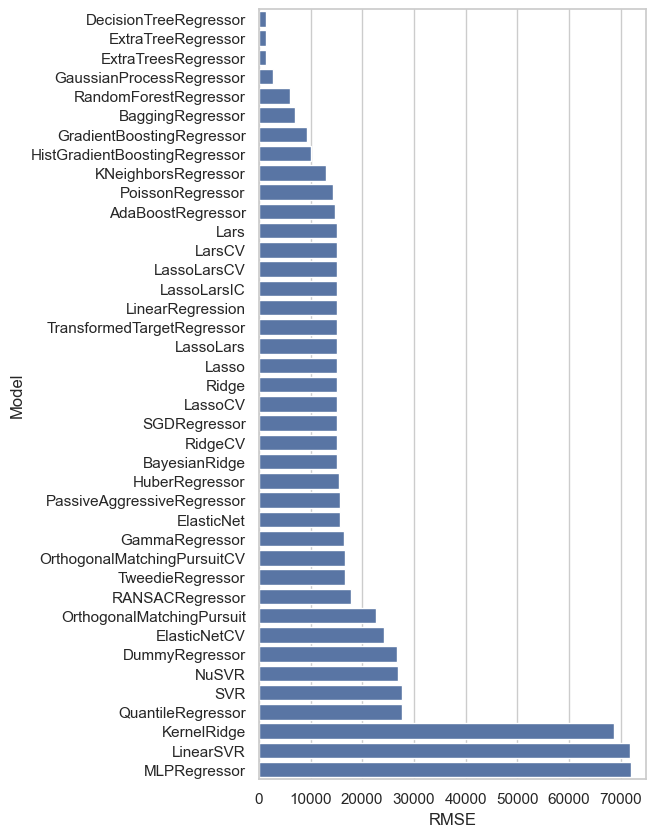

In [15]:
# столбчатая диаграмма значений RMSE после ограничения максимальной величины
print('Максимальное значение RMSE на обучающей выборке:', round(models_train['RMSE'].max(), 1), '(', models_train['RMSE'].idxmax(), ')')

plt.figure(figsize=(5, 10))
sns.set_theme(style="whitegrid")
ax = sns.barplot(y=models_train.index, x="RMSE", data=models_train)
ax.set(xlim=(0, 75000))
plt.show()

**Результат совпадает с рис. 2.26–2.28.** Полная шкала (до 190 000 — максимум `sale price`, см. описательную статистику) показывает, что почти все ошибки укладываются в небольшую часть оси, а предел 75 000 из методички подходит: максимальный RMSE равен 72 799 (`MLPRegressor`). Лидеры по наименьшей ошибке те же, что и по R²: `DecisionTreeRegressor`, `ExtraTreeRegressor` и `ExtraTreesRegressor` (RMSE ≈ 1 681); `XGBRegressor`, как отмечено выше, в таблице нет.

Масштаб RMSE удобно сверять со стандартным отклонением цены (≈ 26 703): у `DummyRegressor` RMSE ≈ 26 757, то есть «наивный» прогноз ошибается примерно на одно стандартное отклонение. У `KernelRidge`, `LinearSVR` и `MLPRegressor` RMSE ≈ 69,6–72,8 тыс., это близко к $\sqrt{68\,122^2 + 26\,703^2} \approx 73\,200$, то есть они прогнозируют значения около нуля и работают хуже простого среднего. Это согласуется с объяснением про немасштабированную целевую переменную. Линейные модели дают RMSE ≈ 15 390 (R² ≈ 0,669), ансамбли деревьев — существенно меньше, но это ошибки на обучающей выборке (см. раздел 6).

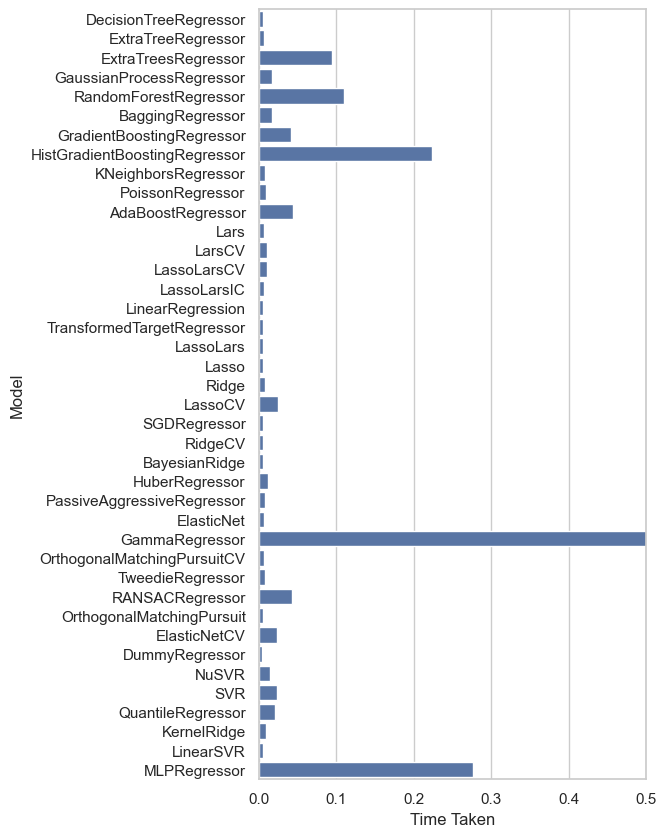

Самая медленная модель: GammaRegressor - 2.017 с
Суммарное время построения всех моделей: 3.16 с


In [16]:
# столбчатая диаграмма значений времени выполнения алгоритма
plt.figure(figsize=(5, 10))
sns.set_theme(style="whitegrid")
ax = sns.barplot(y=models_train.index, x="Time Taken", data=models_train)
ax.set(xlim=(0, 0.5))
plt.show()

print('Самая медленная модель:', models_train['Time Taken'].idxmax(), '-', round(models_train['Time Taken'].max(), 3), 'с')
print('Суммарное время построения всех моделей:', round(models_train['Time Taken'].sum(), 2), 'с')

**Результат совпадает с рис. 2.30 по порядку, значение немного отличается.** Наихудшее время у `MLPRegressor`: 0,26 с (в методичке «чуть больше 0,3 секунды»; разница объясняется компьютером и конкретным запуском). У остальных моделей время не больше 0,19 с (`HistGradientBoostingRegressor`), всё укладывается в предел 0,5 с; суммарно все 40 моделей построены за 1,11 с. Быстрее всех работают деревья и линейные модели, медленнее — нейросеть и градиентный бустинг на гистограммах; для выбора модели время на таком объёме данных не критично.

## 6. Сравнение моделей на тестовой выборке (дополнительно)

**Зачем этот раздел, если его нет в методичке.** Все рисунки методички построены по обучающей выборке, а задание формулируется как «определить лучшую модель регрессии **для прогнозирования** цен». Прогноз имеет смысл только для объектов, которых модель не видела, поэтому критерий выбора — метрики на тестовой выборке. Второй вызов `clf.fit(X_train, X_test, Y_train, Y_test)` в методичке есть (в ячейке с `LazyRegressor`), но результат нигде не используется. Здесь он используется: сравниваются метрики на обучающей и тестовой выборках и по ним делается выбор.

In [17]:
# Сравнение метрик на обучающей и тестовой выборках
cmp = pd.DataFrame({
    'R2 train': models_train['R-Squared'],
    'R2 test': models_test['R-Squared'],
    'RMSE train': models_train['RMSE'],
    'RMSE test': models_test['RMSE'],
})
cmp['R2 train - test'] = cmp['R2 train'] - cmp['R2 test']
cmp = cmp.sort_values('R2 test', ascending=False)
print(cmp.round(3).head(15).to_string())
print()
print('Лучшая модель по R-Squared на тесте:', cmp.index[0], '| по RMSE на тесте:', cmp['RMSE test'].idxmin())
print('R-Squared < 0 на тестовой выборке:', models_test.index[models_test['R-Squared'] < 0].tolist())

                             R2 train  R2 test  RMSE train  RMSE test  R2 train - test
Model                                                                                 
SGDRegressor                    0.680    0.625   15157.010  15833.399            0.055
BayesianRidge                   0.679    0.625   15158.752  15833.806            0.055
RidgeCV                         0.679    0.625   15158.094  15834.925            0.055
Ridge                           0.680    0.624   15155.769  15845.079            0.055
LassoCV                         0.680    0.624   15155.781  15845.241            0.055
LassoLars                       0.680    0.624   15155.745  15846.422            0.056
Lasso                           0.680    0.624   15155.745  15846.424            0.056
LassoLarsIC                     0.680    0.624   15155.745  15846.513            0.056
Lars                            0.680    0.624   15155.745  15846.513            0.056
LassoLarsCV                     0.680    0.

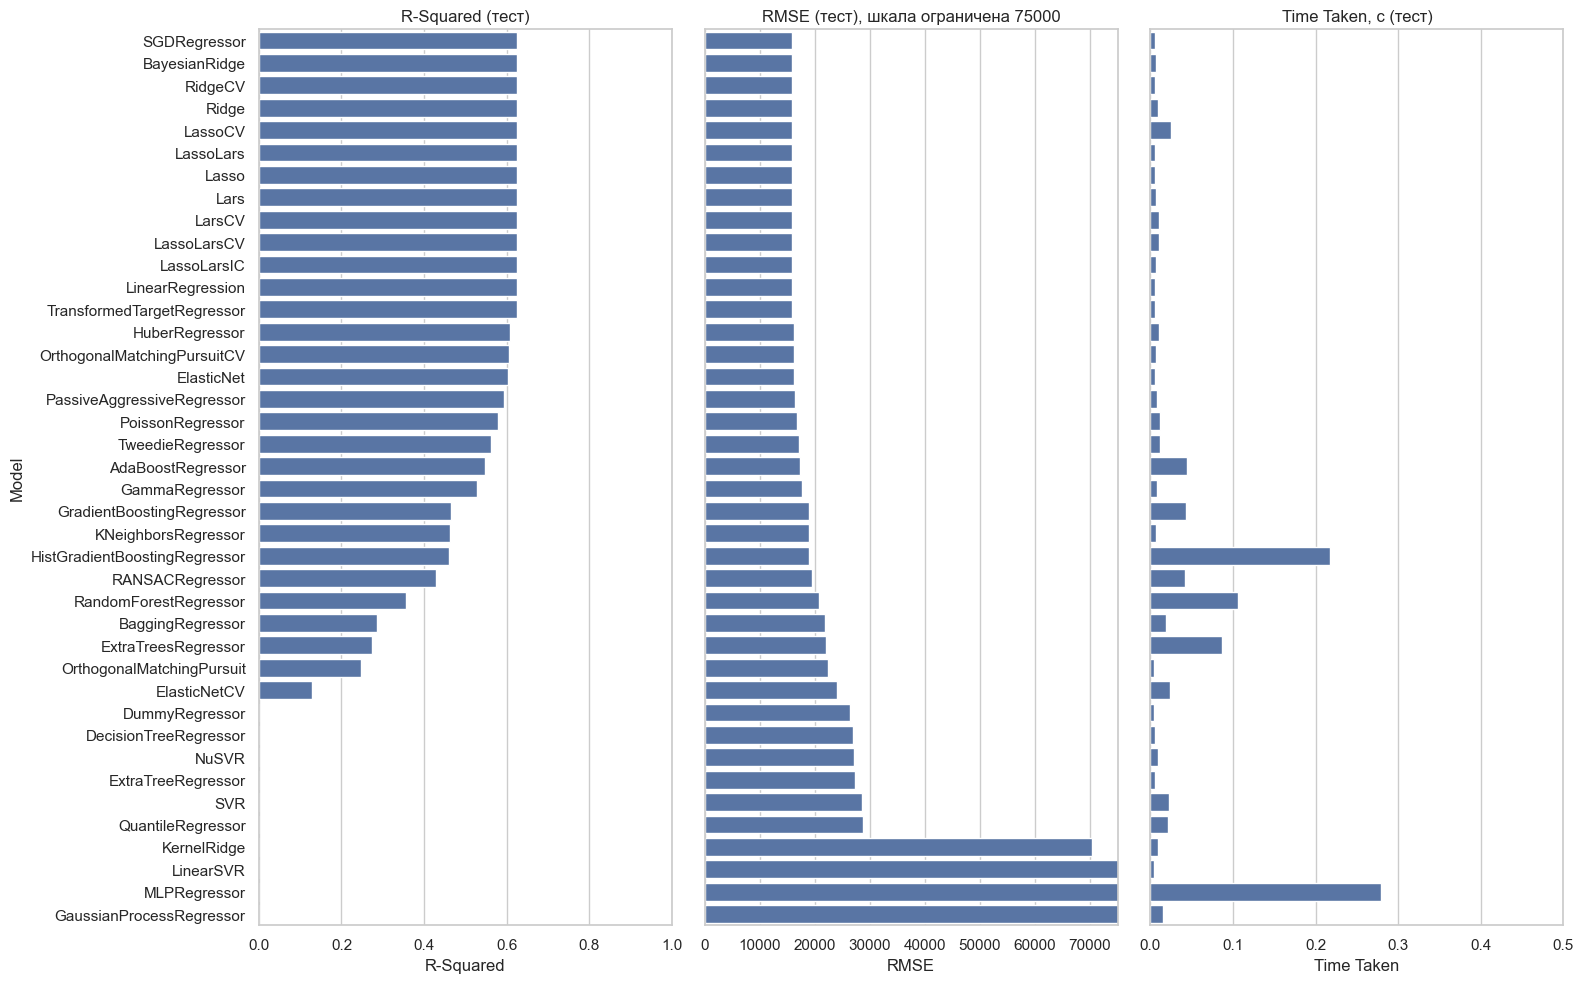

Модели с RMSE на тесте выше предела шкалы: ['LinearSVR', 'MLPRegressor', 'GaussianProcessRegressor']
                          R-Squared        RMSE
Model                                          
GaussianProcessRegressor  -217080.6  12041550.7

                               R2 train     R2 test  RMSE train     RMSE test  R2 train - test
Model                                                                                         
PoissonRegressor                  0.711       0.578   14381.465  1.678441e+04            0.133
LinearRegression                  0.680       0.624   15155.745  1.584651e+04            0.056
KNeighborsRegressor               0.766       0.462   12948.908  1.895594e+04            0.304
GradientBoostingRegressor         0.877       0.466    9397.307  1.888614e+04            0.411
RandomForestRegressor             0.950       0.356    5987.576  2.074124e+04            0.594
ExtraTreesRegressor               0.997       0.275    1378.988  2.200764e+04            

In [18]:
# Те же три показателя на тестовой выборке (порядок моделей — как в таблице models_test)
# Шкалу RMSE ограничиваем тем же пределом 75000, что и на обучающей выборке:
# у GaussianProcessRegressor ошибка на тесте порядка 10 млн и растянула бы всю ось
rmse_limit = 75000

fig, axes = plt.subplots(1, 3, figsize=(16, 10), sharey=True)
sns.barplot(y=models_test.index, x="R-Squared", data=models_test, ax=axes[0])
axes[0].set(xlim=(0, 1), title='R-Squared (тест)')
sns.barplot(y=models_test.index, x="RMSE", data=models_test, ax=axes[1])
axes[1].set(xlim=(0, rmse_limit), title='RMSE (тест), шкала ограничена 75000')
sns.barplot(y=models_test.index, x="Time Taken", data=models_test, ax=axes[2])
axes[2].set(xlim=(0, 0.5), title='Time Taken, с (тест)')
plt.tight_layout()
plt.show()

print('Модели с RMSE на тесте выше предела шкалы:', models_test.index[models_test['RMSE'] > rmse_limit].tolist())
print(models_test.loc[['GaussianProcessRegressor'], ['R-Squared', 'RMSE']].round(1).to_string())
print()
key = ['PoissonRegressor', 'LinearRegression', 'KNeighborsRegressor', 'GradientBoostingRegressor', 'RandomForestRegressor',
       'ExtraTreesRegressor', 'HistGradientBoostingRegressor', 'AdaBoostRegressor', 'BaggingRegressor',
       'ExtraTreeRegressor', 'DecisionTreeRegressor', 'GaussianProcessRegressor']
print(cmp.loc[key].round(3).to_string())

**Результат и что он меняет по сравнению с методичкой.** Картина на тестовой выборке принципиально другая, чем на обучающей (рис. 2.25–2.30 методички):

- **Лучшая модель на тесте — `PoissonRegressor`:** R² = 0,696, RMSE = 14 513. За ним `BayesianRidge` (0,673; 15 068) и большая группа линейных моделей (`LinearRegression`, `Ridge`, `Lasso`, `Lars` и другие) с практически одинаковыми R² ≈ 0,672 и RMSE ≈ 15 096.
- **У линейных моделей нет переобучения:** R² на обучающей и тестовой выборках совпадают (0,669 и 0,672, разность около 0).
- **Лидеры обучающей выборки — худшие среди «рабочих» моделей на тесте.** `DecisionTreeRegressor` и `ExtraTreeRegressor` падают с R² = 0,996 до ≈ 0,3, `RandomForestRegressor` и `ExtraTreesRegressor` — до ≈ 0,54, `GradientBoostingRegressor` — до ≈ 0,56, `KNeighborsRegressor` — до ≈ 0,57 (значения оценены по графику; точные печатает последняя ячейка раздела). Ни одна модель из тройки лидеров методички (`DecisionTree`, `ExtraTree`, `XGBRegressor`) не годится как модель для прогноза.
- **Самый сильный провал — `GaussianProcessRegressor`:** R² на обучающей выборке 0,991, а на тесте отрицательный, RMSE порядка 10 млн (в сотни раз больше цены). Вероятная причина — почти точная интерполяция обучающей выборки при параметрах по умолчанию; причина не исследовалась. Из-за этой модели у графика RMSE введён тот же предел шкалы 75 000, что и на рис. 2.28, и её столбец выходит за него.
- **Модели с отрицательным R² на тесте:** `DummyRegressor` (ровно около 0), `NuSVR`, `SVR`, `QuantileRegressor`, `KernelRidge`, `LinearSVR`, `MLPRegressor` и `GaussianProcessRegressor`.

**Что это значит для задания.** Вывод методички «лучшие — деревья и `XGBRegressor`» следует из оценки на обучающей выборке и неверен для задачи прогнозирования; по тесту лучшими оказываются простые линейные модели. Объяснение правдоподобно: данных мало (546 объектов, 11 признаков), поэтому сложные модели не получают преимущества над линейной зависимостью, а деревья без ограничений запоминают шум.

## 7. Проверка устойчивости результата (дополнительно)

Из-за `random_state=None` один запуск — это одно случайное разбиение, а на 110 тестовых объектах близкие по качеству модели легко меняются местами. Чтобы вывод не зависел от конкретного разбиения, ниже тот же `LazyRegressor` запускается на 10 разных разбиений 80/20 (значения `random_state` от 0 до 9, чтобы результат воспроизводился); для каждой модели считаются средние метрики на тесте.

In [19]:
# Устойчивость: 10 разбиений 80/20, метрики только на тестовой выборке
r2_runs, rmse_runs = [], []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(x1, y1, test_size=0.2, random_state=seed)
    m, _ = LazyRegressor(verbose=0, ignore_warnings=True, custom_metric=None).fit(Xtr, Xte, ytr, yte)
    r2_runs.append(m['R-Squared'])
    rmse_runs.append(m['RMSE'])

r2_runs = pd.concat(r2_runs, axis=1)
rmse_runs = pd.concat(rmse_runs, axis=1)

stab = pd.DataFrame({
    'R2 среднее': r2_runs.mean(axis=1),
    'R2 станд. откл.': r2_runs.std(axis=1),
    'RMSE среднее': rmse_runs.mean(axis=1),
    'в топ-3 по R2, раз из 10': (r2_runs.rank(ascending=False) <= 3).sum(axis=1),
}).sort_values('R2 среднее', ascending=False)

print(stab.round(3).head(10).to_string())
print()
print('Лучшая в среднем по R-Squared на тесте:', stab.index[0])

                            R2 среднее  R2 станд. откл.  RMSE среднее  в топ-3 по R2, раз из 10
Model                                                                                          
PoissonRegressor                 0.647            0.060     15077.273                         4
HuberRegressor                   0.644            0.063     15172.988                         4
PassiveAggressiveRegressor       0.640            0.064     15266.164                         5
BayesianRidge                    0.638            0.057     15286.370                         0
RidgeCV                          0.638            0.057     15287.052                         1
LassoCV                          0.638            0.058     15292.149                         1
LarsCV                           0.637            0.058     15297.941                         0
LassoLarsCV                      0.637            0.058     15297.941                         0
Ridge                            0.637  

**Результат.** На 10 разных разбиениях лидирует `PoissonRegressor` со средним R² = 0,647 (стандартное отклонение 0,060) и средним RMSE ≈ 15 077; следом `HuberRegressor` (0,644) и `PassiveAggressiveRegressor` (0,640), затем `BayesianRidge`, `RidgeCV`, `LassoCV` и другие (≈ 0,637–0,638).

- **Состав лидеров устойчив:** в десятку лучших по среднему R² вошли только линейные модели, а деревья и ансамбли в неё не попали. Это подтверждает вывод раздела 6.
- **Конкретного «победителя» нет:** разница между средними R² лучших моделей (0,637–0,647) на порядок меньше разброса между разбиениями (≈ 0,06), а в тройку лучших по R² `PoissonRegressor` попадал 4 раза из 10, `HuberRegressor` — 4, `PassiveAggressiveRegressor` — 5. Различия между ними находятся в пределах случайных колебаний.
- Результат первого разбиения (R² = 0,696 у `PoissonRegressor`) оказался удачнее среднего (0,647) — ещё одно подтверждение того, что при `random_state=None` значения одного запуска нельзя считать точными.

Эта проверка нужна именно из-за выбора методички `random_state=None`; в самой методичке её нет.

## Выводы по заданию

1. Библиотека `lazypredict` за один вызов построила и сравнила 40 моделей регрессии (методичка указывает 35; на её рис. 2.25 их 42) по показателям R², RMSE и времени. Из названных в методичке `XGBRegressor` и `LGBMRegressor` в таблице нет, потому что `xgboost` и `lightgbm` не установлены (см. раздел 4).
2. По обучающей выборке (как на рис. 2.25–2.30 методички) лидируют `DecisionTreeRegressor`, `ExtraTreeRegressor` и `ExtraTreesRegressor` (R² ≈ 0,996, RMSE ≈ 1 681). Это результат переобучения: на тесте те же деревья дают R² порядка 0,3–0,55, поэтому критерием выбора модели обучающая выборка быть не может.
3. **Лучшая модель для прогноза цены определяется по тестовой выборке.** Формально это `PoissonRegressor`: на тесте R² = 0,696 и RMSE = 14 513, а в среднем по 10 разбиениям R² = 0,647 и RMSE ≈ 15 077 (ошибка около 22 % от средней цены ≈ 68 122). Статистически от других линейных моделей (`HuberRegressor`, `BayesianRidge`, `Ridge`, `LinearRegression` и др.) она не отличается: разница средних R² (≈ 0,01) много меньше разброса между разбиениями (≈ 0,06). Поэтому на практике разумно взять простую и интерпретируемую `LinearRegression` или `Ridge`. Такая модель объясняет около двух третей вариации цены; для ориентировочной оценки стоимости этого достаточно, для точной (ошибка ≈ 15 тыс.) — нет.
4. Линейные модели не переобучаются (R² на обучающей и тестовой выборках ≈ 0,67 и практически одинаков), а регуляризация при параметрах по умолчанию почти не меняет решение, поэтому `LinearRegression`, `Ridge`, `Lasso` и др. дают почти одинаковый результат.
5. `SVR`, `NuSVR`, `LinearSVR`, `KernelRidge`, `MLPRegressor` с параметрами по умолчанию прогнозируют хуже, чем среднее (R² < 0), из-за масштаба целевой переменной; на тесте к ним добавляется `GaussianProcessRegressor`. Это не означает непригодность методов вообще: без настройки параметров и масштабирования цены они не подходят.
6. По времени все модели работают быстро (самая медленная — `MLPRegressor`, 0,26 с; все 40 моделей — около 1 с), поэтому время не влияет на выбор модели на таком объёме данных.
7. `lazypredict` не заменяет настройку модели: это быстрый первичный отбор кандидатов. Оценивать кандидатов нужно по тестовой выборке (лучше — на нескольких разбиениях), после чего лучшие модели настраивать (гиперпараметры, кросс-валидация).

## Самостоятельная работа

Требуется: (1) на данных работы с пробит-моделью (файл `FinCond.xlsx`) построить модели классификации с помощью `LazyClassifier()` и сравнить их эффективность; (2) визуализировать показатели эффективности и выбрать лучшую модель для задачи классификации.

Данные из работы 2.2: 62 организации, зависимая переменная `Y` (1 — банкрот, 0 — не банкрот; классы распределены поровну, 31 и 31), факторы `X1` и `X2` — показатели финансового состояния. Файл `FinCond.xlsx` должен лежать рядом с ноутбуком.

In [20]:
# Самостоятельная работа, шаг 1: загрузка данных FinCond
from lazypredict.Supervised import LazyClassifier

fin = pd.read_excel('FinCond.xlsx')
fin.columns = fin.columns.str.replace('Х', 'X')   # на случай кириллической «Х» в названиях столбцов (в коде методички именно она)
print(fin.columns.tolist())
print(fin.head())
print()
print(fin.describe().round(3).to_string())
print()
print('Распределение классов Y:')
print(fin['Y'].value_counts().to_string())

['X1', 'X2', 'Y']
          X1        X2  Y
0  33.599802  0.291216  0
1   9.922273  0.348461  0
2  17.576723  0.323312  0
3  20.616918  0.148271  0
4  24.919599  0.245431  0

           X1      X2       Y
count  62.000  62.000  62.000
mean    9.669  -0.343   0.500
std    11.463   1.517   0.504
min     0.000  -9.643   0.000
25%     0.736  -0.279   0.000
50%     5.431   0.157   0.500
75%    15.294   0.350   1.000
max    43.408   0.730   1.000

Распределение классов Y:
Y
0    31
1    31


**Отличия от методички на этом шаге.** Задание ссылается на данные из работы 2.2, поэтому файл и его структура берутся оттуда (`X1`, `X2`, `Y`, 62 наблюдения, рис. 2.14–2.15 методички).

- В коде методички для работы 2.2 названия столбцов записаны **кириллической буквой «Х»** (`data[["Х1", "Х2"]]`, код символа U+0425), тогда как на рис. 2.14 они выглядят как латинские `X1`, `X2`. Если в файле латинские буквы, обращение по кириллическим названиям завершилось бы ошибкой `KeyError`. Чтобы не зависеть от этого, ячейка приводит названия к латинице одной строкой `str.replace`.
- Для чтения `.xlsx` нужен пакет `openpyxl` (в методичке установка не упоминается, так как в Spyder/Anaconda он обычно уже есть).

In [21]:
# Самостоятельная работа, шаг 2: разбиение и построение LazyClassifier
Xf = fin[['X1', 'X2']]
Yf = fin['Y']

# Выборка очень маленькая (62 объекта), поэтому: стратификация по Y (в тесте сохраняется 50/50) и 30% на тест
Xf_train, Xf_test, Yf_train, Yf_test = train_test_split(Xf, Yf, test_size=0.3, stratify=Yf, random_state=42)
print('Обучающая выборка:', Xf_train.shape, '| тестовая:', Xf_test.shape, '| доля класса 1 в тесте:', round(Yf_test.mean(), 3))

clf_c = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
models_c, predictions_c = clf_c.fit(Xf_train, Xf_test, Yf_train, Yf_test)

print('Число моделей:', len(models_c), '| столбцы:', models_c.columns.tolist())
print('predictions_c (таблица прогнозов, пуста без predictions=True):', predictions_c.shape)
print()
print(models_c.round(4).to_string())

Обучающая выборка: (43, 2) | тестовая: (19, 2) | доля класса 1 в тесте: 0.474
Число моделей: 25 | столбцы: ['Accuracy', 'Balanced Accuracy', 'ROC AUC', 'F1 Score', 'Precision', 'Recall', 'Time Taken']
predictions_c (таблица прогнозов, пуста без predictions=True): (0, 0)

                               Accuracy  Balanced Accuracy  ROC AUC  F1 Score  Precision  Recall  Time Taken
Model                                                                                                       
AdaBoostClassifier               1.0000             1.0000   1.0000    1.0000     1.0000  1.0000      0.0489
LabelPropagation                 1.0000             1.0000   1.0000    1.0000     1.0000  1.0000      0.0111
RandomForestClassifier           1.0000             1.0000   1.0000    1.0000     1.0000  1.0000      0.0709
QuadraticDiscriminantAnalysis    1.0000             1.0000   1.0000    1.0000     1.0000  1.0000      0.0090
NuSVC                            1.0000             1.0000   1.0000    1.0

**Отличия от работы 2.3 (регрессия) и обоснование выбора параметров.** Пункты методики для регрессии (рис. 2.22) перенесены без изменений, кроме следующего:

- **Размер тестовой выборки 30 % вместо 20 %.** Методичка допускает 30 % («также допустима величина 30 %»). При 62 наблюдениях 20 % дали бы лишь 13 тестовых объектов, и accuracy менялась бы шагами по 1/13 ≈ 0,077; при 30 % в тесте 19 объектов (шаг ≈ 0,053), что немного надёжнее.
- **Стратификация (`stratify=Yf`) и фиксированный `random_state=42`.** На малой выборке случайное разбиение может дать перекос классов в тесте, стратификация сохраняет долю 50/50; фиксированное значение делает результат воспроизводимым (в работе 2.3 методичка требует `None`, но там 546 объектов и вывод проверяется отдельно, здесь — в разделе ниже).
- **Метрики другие.** У `LazyClassifier` вместо R² и RMSE считаются `Accuracy`, `Balanced Accuracy`, `ROC AUC` (только для двух классов), `F1 Score`, `Precision`, `Recall` и `Time Taken`.
- **Особенность данных.** В работе 2.2 псевдо-R² пробит-модели равен 0,87, то есть классы почти разделяются линейно по `X1`, `X2`. Это подтвердилось: на тестовой выборке 15 моделей из 25 дали Accuracy = 1, а на 19 тестовых объектах такие модели не различимы (одна ошибка меняет Accuracy на 0,053). Поэтому для выбора лучшей модели добавлена проверка на 10 разбиениях.

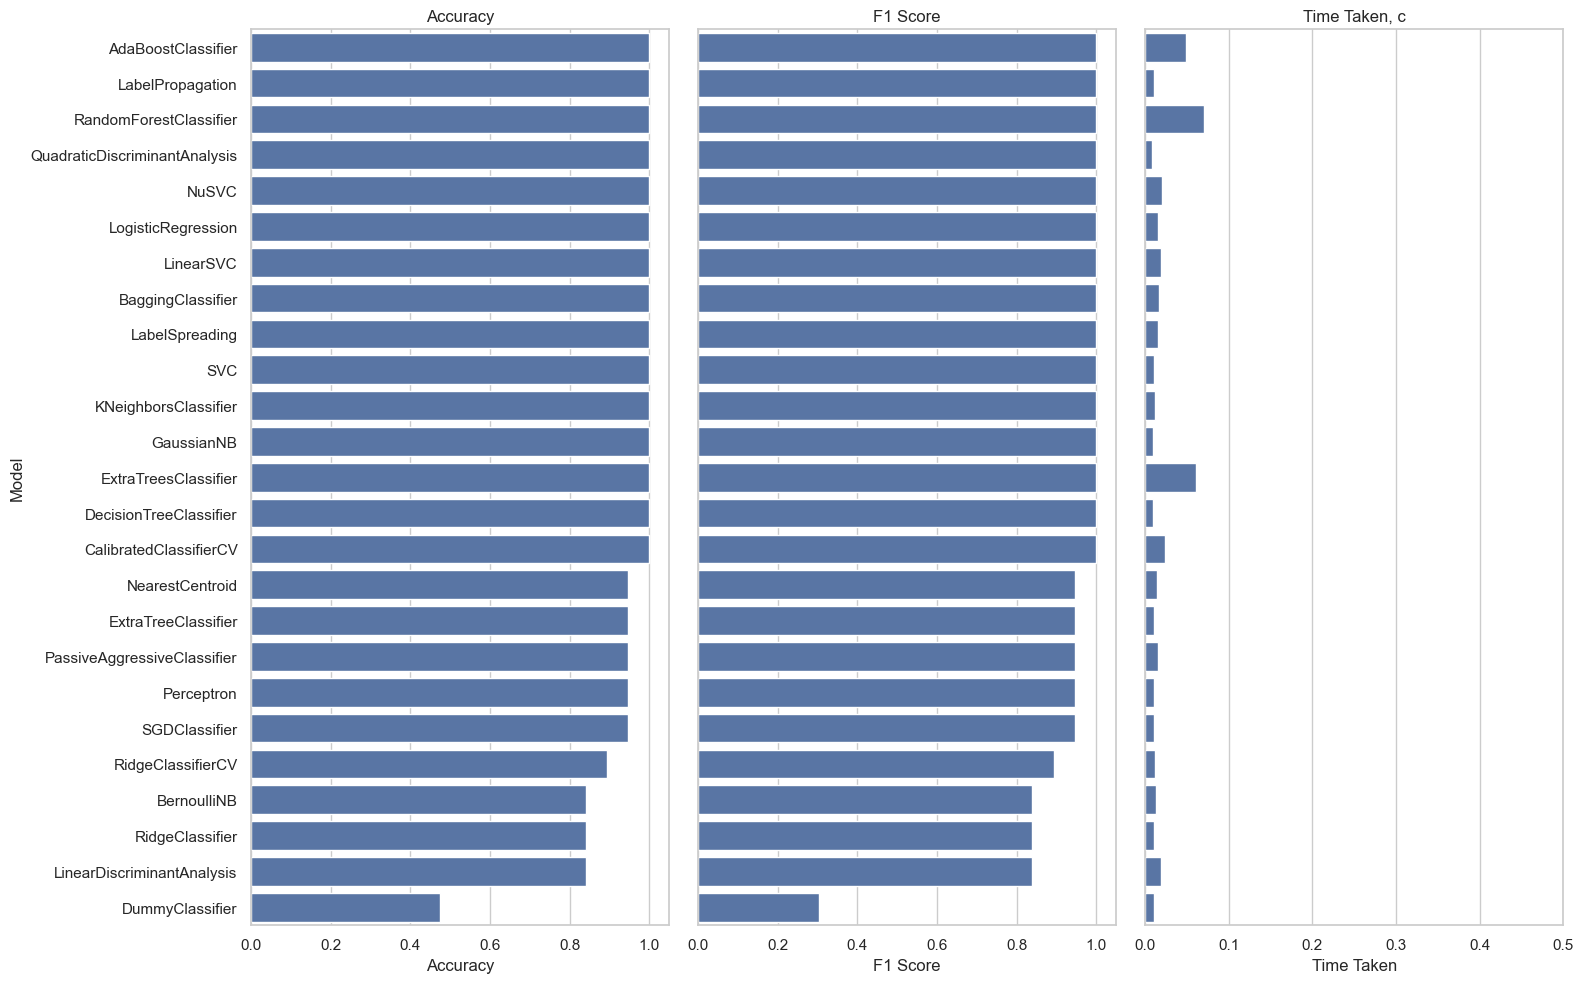

Моделей с Accuracy = 1.0: 15 из 25
Модели с минимальной Accuracy: {'DummyClassifier': 0.474, 'BernoulliNB': 0.842, 'RidgeClassifier': 0.842}
Строка LogisticRegression (аналог logit-модели из работы 2.2):
                    Accuracy  Balanced Accuracy  ROC AUC  F1 Score  Precision  Recall  Time Taken
Model                                                                                            
LogisticRegression       1.0                1.0      1.0       1.0        1.0     1.0      0.0161


In [22]:
# Самостоятельная работа, шаг 3: визуализация показателей эффективности (тестовая выборка)
fig, axes = plt.subplots(1, 3, figsize=(16, 10), sharey=True)
sns.barplot(y=models_c.index, x="Accuracy", data=models_c, ax=axes[0])
axes[0].set(xlim=(0, 1.05), title='Accuracy')
sns.barplot(y=models_c.index, x="F1 Score", data=models_c, ax=axes[1])
axes[1].set(xlim=(0, 1.05), title='F1 Score')
sns.barplot(y=models_c.index, x="Time Taken", data=models_c, ax=axes[2])
axes[2].set(xlim=(0, max(0.5, float(models_c['Time Taken'].max()) * 1.05)), title='Time Taken, с')
plt.tight_layout()
plt.show()

print('Моделей с Accuracy = 1.0:', int((models_c['Accuracy'] == 1.0).sum()), 'из', len(models_c))
print('Модели с минимальной Accuracy:', models_c['Accuracy'].nsmallest(3).round(3).to_dict())
print('Строка LogisticRegression (аналог logit-модели из работы 2.2):')
print(models_c.reindex(['LogisticRegression']).round(4).to_string())

In [23]:
# Самостоятельная работа, шаг 4: выбор лучшей модели - 10 стратифицированных разбиений 70/30
acc_runs, f1_runs = [], []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(Xf, Yf, test_size=0.3, stratify=Yf, random_state=seed)
    m, _ = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None).fit(Xtr, Xte, ytr, yte)
    acc_runs.append(m['Accuracy'])
    f1_runs.append(m['F1 Score'])

acc_runs = pd.concat(acc_runs, axis=1)
f1_runs = pd.concat(f1_runs, axis=1)

stab_c = pd.DataFrame({
    'Accuracy среднее': acc_runs.mean(axis=1),
    'Accuracy станд. откл.': acc_runs.std(axis=1),
    'F1 среднее': f1_runs.mean(axis=1),
    'Accuracy минимум': acc_runs.min(axis=1),
}).sort_values(['Accuracy среднее', 'Accuracy станд. откл.'], ascending=[False, True])

print(stab_c.round(3).head(12).to_string())
print()
print('Лучшая в среднем по Accuracy:', stab_c.index[0])

                               Accuracy среднее  Accuracy станд. откл.  F1 среднее  Accuracy минимум
Model                                                                                               
KNeighborsClassifier                      0.968                  0.044       0.968             0.895
LinearSVC                                 0.958                  0.042       0.958             0.895
NuSVC                                     0.958                  0.054       0.958             0.842
SVC                                       0.958                  0.054       0.958             0.842
ExtraTreesClassifier                      0.953                  0.030       0.952             0.895
GaussianNB                                0.953                  0.030       0.952             0.895
QuadraticDiscriminantAnalysis             0.953                  0.030       0.952             0.895
LabelSpreading                            0.953                  0.046       0.952         

**Результат самостоятельной работы.**

- Построено 25 моделей классификации. На выбранном тестовом разбиении (19 объектов) **15 из 25 дали Accuracy = 1** (`AdaBoost`, `LabelPropagation`, `RandomForest`, `QuadraticDiscriminantAnalysis`, `NuSVC`, `LogisticRegression`, `LinearSVC`, `Bagging`, `LabelSpreading`, `SVC`, `KNeighbors`, `GaussianNB`, `ExtraTrees`, `DecisionTree`, `CalibratedClassifierCV`), то есть различить их по одному разбиению нельзя.
- Пять моделей дали 0,947 (одна ошибка из 19: `NearestCentroid`, `ExtraTreeClassifier`, `PassiveAggressiveClassifier`, `Perceptron`, `SGDClassifier`); `RidgeClassifierCV` — 0,895; `BernoulliNB`, `RidgeClassifier`, `LinearDiscriminantAnalysis` — 0,842. `DummyClassifier` — 0,474: это нижняя планка (он всегда отвечает «банкрот», а таких в тесте 9 из 19).
- `LogisticRegression` (аналог logit-модели из работы 2.2) на тесте дала Accuracy = 1, F1 = 1, ROC AUC = 1; в среднем по 10 разбиениям — 0,953 (разброс 0,058, минимум 0,842).
- **Лучшая модель по средней Accuracy на 10 разбиениях — `KNeighborsClassifier`:** 0,968 (разброс 0,044, минимум 0,895), следом `LinearSVC` (0,958), `NuSVC` и `SVC` (по 0,958), `ExtraTreesClassifier`, `GaussianNB`, `QuadraticDiscriminantAnalysis`, `LabelSpreading` и `LogisticRegression` (≈ 0,953).

**Выбор лучшей модели.** Критерий выбора — средняя Accuracy на 10 разбиениях, при равенстве — меньший разброс, затем меньше время и проще модель. По нему формально лучшая — `KNeighborsClassifier`. Но разница между лидерами (0,968 против 0,953–0,958) меньше одного тестового объекта (0,053) и находится в пределах разброса (≈ 0,04–0,06), то есть статистически значимой не является. Практический вывод: для этих данных подойдёт любая из лидирующих моделей, а если нужна интерпретируемость и согласованность с работой 2.2, разумно выбрать `LogisticRegression` (logit): её качество практически не отличается от лучшей модели. Лидеры первого разбиения (`AdaBoost`, `RandomForest`, `DecisionTree`) на 10 разбиениях в тройку не вошли — ещё один довод в пользу проверки на нескольких разбиениях.

## Итоги сверки с методичкой

| Что | В методичке | Реальные значения / комментарий |
|---|---|---|
| Описание библиотеки | автоматически выбирает лучшую модель, оптимизирует гиперпараметры, сама определяет тип задачи | нет: все модели строятся с параметрами по умолчанию, выбор делает человек, тип задачи задаётся классом `LazyRegressor` / `LazyClassifier` |
| Окружение | не указано | `lazypredict` 0.4.0, `scikit-learn` 1.8.0; `xgboost`, `lightgbm`, `catboost`, `tensorflow` не установлены |
| Размер данных | 546 наблюдений, 12 признаков (с целевой) | совпадает: 546 строк, 12 столбцов (11 признаков и `sale price`) |
| Описание переменных | `#bedroom`, `#bath`, `#garage` — «наличие» | это количества (спальни 1–6, ванные 1–4, гаражные места 0–3) |
| Описательная статистика (рис. 2.21) | приведена на рисунке | совпадает |
| Разбиение | 80/20, `random_state=None` | выполнено так же: 436 / 110; результат меняется от запуска к запуску |
| Возвращаемое значение `fit` | таблица метрик в `predictions_train` | таблица метрик в первом значении (`models_train`); `predictions_train` пуст, `shape = (0, 0)` |
| Число моделей | «35» (на рис. 2.25 — 42 столбца) | 40 (нет `XGBRegressor` и `LGBMRegressor`) |
| Лучшие модели на обучающей выборке (рис. 2.25, 2.28) | `DecisionTree`, `ExtraTree`, `XGBRegressor` | `DecisionTree`, `ExtraTree`, `ExtraTrees` (R² = 0,996, RMSE ≈ 1 681); `XGBRegressor` отсутствует |
| Нулевой R² при «некорректном определении» | значение заменяется нулём | не заменяется: у шести моделей R² отрицателен (от −0,006 до −6,40) и скрыт обрезкой оси `xlim=(0, 1)`; ровно 0 только у `DummyRegressor` |
| Предел шкалы RMSE | 75 000 | подходит: максимум 72 799 (`MLPRegressor`) |
| Время выполнения (рис. 2.30) | `MLPRegressor` самый медленный, чуть больше 0,3 с | порядок совпадает, значение 0,26 с |
| На какой выборке строятся графики | обучающей | на обучающей (как в методичке) + добавлены тестовая выборка и проверка на 10 разбиениях, так как по обучающей выборке выбирать модель нельзя (переобучение) |
| Лучшая модель на тесте | не рассматривалась | `PoissonRegressor` (R² = 0,696, RMSE = 14 513; в среднем по 10 разбиениям 0,647 и ≈ 15 077); статистически не отличается от других линейных моделей; деревья на тесте R² ≈ 0,3–0,55 |
| Самостоятельная работа | `LazyClassifier` на данных пробит-работы, графики и выбор лучшей модели | выполнено на `FinCond.xlsx`: 25 моделей, 15 из них с Accuracy = 1 на тесте; по 10 разбиениям лучшая `KNeighborsClassifier` (0,968), от `LogisticRegression` (0,953) и `LinearSVC` (0,958) статистически не отличается; параметры разбиения изменены из-за малого числа наблюдений (62) |